C = 1.3155


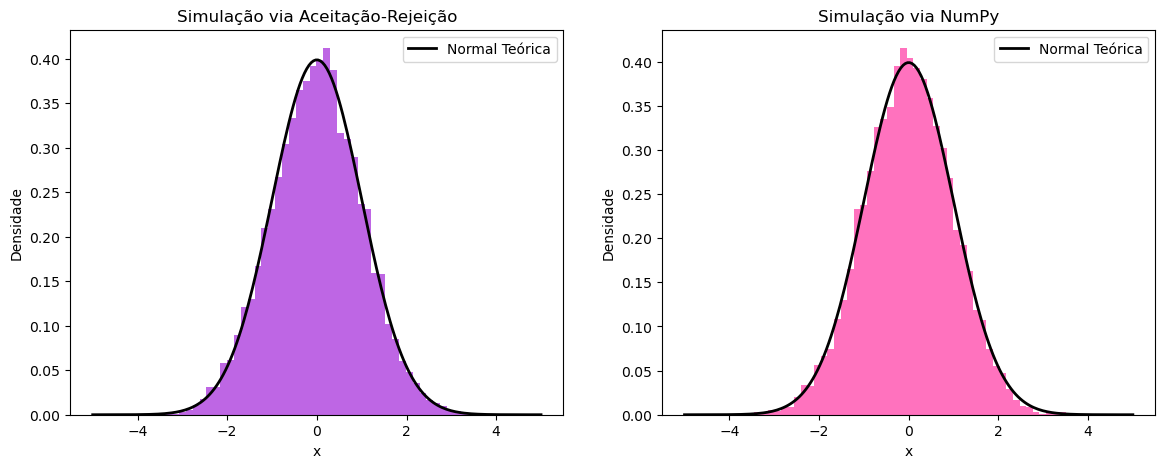

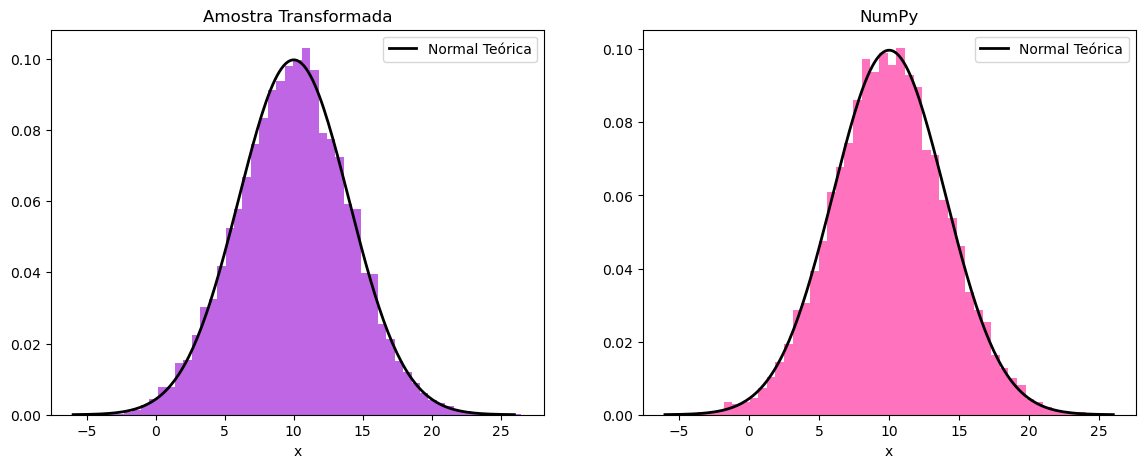

Taxa de aceitação empírica: 0.7612
Taxa de aceitação teórica (1/c): 0.7602


In [16]:
import numpy as np
import math

#1. encontrando o valor de c
n = 10000 
c = math.sqrt(2 * math.e / math.pi) 

print(f"C = {c:.4f}")

#2. algoritmo AR para gerar uma amostra de tamanho n da distribuição normal(0,1)
amostra = []

#registrando o numero de propostas geradas para calcular a taxa empirica do item 6
propostas_geradas = 0

while len(amostra) < n:
    propostas_geradas += 1
    u1 = np.random.uniform(0, 1)
    y = -math.log(u1)
    u2 = np.random.uniform(0, 1)
    
    probabilidade_aceitacao = math.exp(-((y - 1)**2) / 2)
   
    if u2 <= probabilidade_aceitacao:
        amostra.append(y)

#3 sorteando sinais aleatorios para a normal(0,1)
amostra_normal_padrao = []
for x in amostra:
    
    sinal = np.random.uniform(0, 1)
    if sinal < 0.5:
        amostra_normal_padrao.append(-x) 
    else:
        amostra_normal_padrao.append(x)  

#3.1 gerando amostra da normal padrão com numpy]
normal_padrao_numpy = np.random.normal(0, 1, n)

#3.2 histogramas
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))


eixos[0].hist(amostra_normal_padrao, bins=50, density=True, alpha=0.6, color='darkviolet')
eixos[0].set_title("Simulação via Aceitação-Rejeição")


eixos[1].hist(normal_padrao_numpy, bins=50, density=True, alpha=0.6, color='deeppink')
eixos[1].set_title("Simulação via NumPy")


x_teorico = np.linspace(-5, 5, 200)
y_teorico = (1 / math.sqrt(2 * math.pi)) * np.exp(-x_teorico**2 / 2)

for i in range(2):
    eixos[i].plot(x_teorico, y_teorico, color='black', linewidth=2, label='Normal Teórica')
    eixos[i].set_xlabel("x")
    eixos[i].set_ylabel("Densidade")
    eixos[i].legend()

plt.show()

#4. implementando a transformação para gerar uma normal de tamanho n
mu = 10     
sigma = 4 

amostra_normal_transformada = []

for z in amostra_normal_padrao:
    x = mu + sigma * z
    amostra_normal_transformada.append(x)

#5. gerando amostra da normal com numpy
normal_numpy = np.random.normal(mu, sigma, n)

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

eixos[0].hist(amostra_normal_transformada, bins=50, density=True, alpha=0.6, color='darkviolet')
eixos[0].set_title("Amostra Transformada")
eixos[0].set_xlabel("x")

eixos[1].hist(normal_numpy, bins=50, density=True, alpha=0.6, color='deeppink')
eixos[1].set_title("NumPy")
eixos[1].set_xlabel("x")


x_teorico = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)
y_teorico = (1 / (sigma * math.sqrt(2 * math.pi))) * np.exp(-((x_teorico - mu)**2) / (2 * sigma**2))

for i in range(2):
    eixos[i].plot(x_teorico, y_teorico, color='black', linewidth=2, label='Normal Teórica')
    eixos[i].legend()

plt.show()

#6. calculando a taxa empírica de aceitação
taxa_empirica = n / propostas_geradas

taxa_teorica = 1 / c

print(f"Taxa de aceitação empírica: {taxa_empirica:.4f}")
print(f"Taxa de aceitação teórica (1/c): {taxa_teorica:.4f}")



Comparando a taxa empirica com a probabilidade teórica concluimos que o metodo de
simulaçao utilizado se aproxima do teorico, ou seja, são compativeis 